# Thailand Landslide Susceptibility Dataset — v2 (terrain-realistic non-landslide points)

**Why this notebook exists.** In `07c`, pseudo-absences were drawn uniformly at random from *all of Thailand*
(outside a 1 km buffer). That made the classification trivially easy: non-landslide points were mostly flat
lowland cropland/alluvium (median slope 1.4°, median elevation 174 m) while landslides sit on hillslopes
(median slope 19.6°, 500 m). A model can score ROC-AUC ≈ 0.97 by learning "hills vs. plains", and that
shortcut does not carry over to a country like Sri Lanka where the whole test area is hilly.

**What changes here (only the negative-sampling logic and everything downstream of it):**

| Rule | Purpose |
|---|---|
| Negatives must be ≥ `EXCLUSION_BUFFER_M` from **every** known landslide | avoid unmapped/adjacent landslides labelled as "safe" |
| Negatives must be ≤ `COVERAGE_BUFFER_M` from a known landslide | stay inside the area the DMR inventory actually surveyed (removes regional bias, e.g. geology classes that only occur outside the inventory footprint) |
| Slope ≥ 5th percentile of landslide slope | negatives must be on terrain where a landslide *could* occur |
| Elevation within the 1st–99th percentile of landslide elevation | same idea, for elevation |
| Exclude permanent water, herbaceous wetland, mangroves (ESA 80/90/95) | physically implausible landslide terrain |
| One negative per DEM cell, snapped to cell centres | no duplicated pixels |
| Same number of negatives as unique landslide locations | balanced classes |

Everything else (recurrence-aware unique-location positives, factor list, leakage-safe split, scaler/encoder fitted
on train only) is kept identical to `07c` so `08c` and `09` keep working.

**Prerequisite:** `07c` must already have been run so the factor rasters (`map_*.tif`), the unique-location
inventory and the geology files exist. Nothing is re-downloaded here.

> **Design note (state this in the thesis).** Restricting negatives to the landslide terrain envelope makes the task
> *harder on purpose* and lowers headline accuracy. That is expected: it measures whether the model can separate
> landslide from non-landslide slopes, not hills from plains. Report both the easy (`07c`) and hard (this notebook)
> variants if you want to show the effect of the sampling strategy.

## 0. Imports and configuration

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json
import shutil
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import shapely
from rasterio.windows import Window
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=UserWarning)

print("GeoPandas:", gpd.__version__)
print("Rasterio :", rasterio.__version__)
print("Shapely  :", shapely.__version__)

GeoPandas: 1.1.4
Rasterio : 1.4.4
Shapely  : 2.1.2


In [2]:
# ---------------- Paths (same layout as 07c) ----------------
PROJECT_ROOT = Path.cwd().resolve().parent
DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw" / "Thailand"
PROCESSED_DIR = DATA_DIR / "processed"
FACTOR_DIR = PROCESSED_DIR / "thailand_factors"
GEOLOGY_DIR = RAW_DIR / "geology"

TARGET_CRS = "EPSG:32647"
RANDOM_STATE = 42

# ---------------- Negative-sampling rules ----------------
NEG_TO_POS_RATIO = 1.0          # 1.0 = balanced classes
EXCLUSION_BUFFER_M = 1_000      # min distance to ANY known landslide
COVERAGE_BUFFER_M = 10_000      # max distance to a known landslide (None = whole country)
SLOPE_QUANTILE_LOW = 0.05       # negatives need slope >= this quantile of landslide slope
ELEV_QUANTILES = (0.01, 0.99)   # negatives must lie inside this landslide-elevation range
EXCLUDE_LANDCOVER = [80, 90, 95]  # ESA WorldCover: water, herbaceous wetland, mangroves

CANDIDATES_PER_BATCH = 400_000
MAX_BATCHES = 200

# ---------------- Output naming ----------------
# "_v2" keeps your original 07c outputs untouched so you can compare.
# Set PROMOTE_TO_STANDARD_NAMES=True at the very end to make 08c/09 pick these up without code changes.
SUFFIX = "_v2"
PROMOTE_TO_STANDARD_NAMES = False

USE_RECURRENCE_SAMPLE_WEIGHT = True

# ---------------- Input files produced by 07c ----------------
UNIQUE_GPKG = PROCESSED_DIR / "thailand_landslide_unique_locations.gpkg"
BOUNDARY_PATH = RAW_DIR / "thailand_boundary.gpkg"
GEOLOGY_RAW_PATH = GEOLOGY_DIR / "thailand_glim_geology.gpkg"
GEOLOGY_LEGEND_PATH = PROCESSED_DIR / "thailand_geology_legend.csv"

FACTOR_RASTERS = {
    "elev":      FACTOR_DIR / "map_elev.tif",
    "aspect":    FACTOR_DIR / "map_aspect.tif",
    "planc":     FACTOR_DIR / "map_planc.tif",
    "profc":     FACTOR_DIR / "map_profc.tif",
    "slope":     FACTOR_DIR / "map_slope.tif",
    "spi":       FACTOR_DIR / "map_spi.tif",
    "twi":       FACTOR_DIR / "map_twi.tif",
    "clay":      FACTOR_DIR / "map_clay.tif",
    "sand":      FACTOR_DIR / "map_sand.tif",
    "soc":       FACTOR_DIR / "map_soc.tif",
    "bdod":      FACTOR_DIR / "map_bdod.tif",
    "landcover": FACTOR_DIR / "map_landcover.tif",
}
# The aligned SoilGrids rasters keep native integer units; 07c divided at sampling time, so do the same here.
SOIL_DIVISORS = {"clay": 10.0, "sand": 10.0, "soc": 10.0, "bdod": 100.0}

continuous_factor_columns = ["elev", "aspect", "planc", "profc", "slope", "spi", "twi",
                             "clay", "sand", "soc", "bdod"]
categorical_factor_columns = ["landcover", "geologi"]
model_factor_columns = continuous_factor_columns + categorical_factor_columns

missing_inputs = [str(p) for p in [UNIQUE_GPKG, BOUNDARY_PATH, GEOLOGY_RAW_PATH, *FACTOR_RASTERS.values()]
                  if not Path(p).exists()]
if missing_inputs:
    raise FileNotFoundError("Run 07c first. Missing:\n" + "\n".join(missing_inputs))

with rasterio.open(FACTOR_RASTERS["elev"]) as ref:
    print("Reference DEM grid :", ref.shape, "| CRS:", ref.crs, "| resolution:", ref.res)
    REF_RES = ref.res[0]
print("\nNOTE: 07c's text says 30 m but the DEM it actually built is SRTM GL3 (~90 m).")
print("Sri Lanka's terrain layers come from a 30 m SRTM DEM, so slope/TWI/SPI/curvature are not")
print("scale-comparable unless one side is resampled. This notebook keeps the grid as-is.")

Reference DEM grid : (18409, 10208) | CRS: EPSG:32647 | resolution: (90.0, 90.0)

NOTE: 07c's text says 30 m but the DEM it actually built is SRTM GL3 (~90 m).
Sri Lanka's terrain layers come from a 30 m SRTM DEM, so slope/TWI/SPI/curvature are not
scale-comparable unless one side is resampled. This notebook keeps the grid as-is.


## 1. Load the unique-location landslide inventory (positives)

In [3]:
positives = gpd.read_file(UNIQUE_GPKG).to_crs(TARGET_CRS)

required_cols = ["location_id", "landslide_count", "recurrence_proxy_flag",
                 "recurrence_class", "recurrence_weight"]
missing_cols = [c for c in required_cols if c not in positives.columns]
if missing_cols:
    raise ValueError(f"Unique-location file is missing {missing_cols}")

positives = positives.reset_index(drop=True)
positives["X"] = positives.geometry.x
positives["Y"] = positives.geometry.y
positives["label"] = 1
positives["lslpts"] = "TRUE"
positives["source"] = "Thailand_DMR_Landslide_Inventory"

assert not positives["location_id"].duplicated().any()
assert not positives.geometry.duplicated().any()

print("Unique landslide locations:", len(positives))
positives[["location_id", "landslide_count", "X", "Y"]].head()

Unique landslide locations: 54821


,location_id,landslide_count,X,Y
0,LSL_000001,1,352828.0,2038314.0
1,LSL_000002,1,353499.0,2037948.0
2,LSL_000003,1,355194.0,2034322.0
3,LSL_000004,1,356570.0,2038677.0
4,LSL_000005,1,357147.0,2032875.0


## 2. Raster sampling helper

Reads the rasters in horizontal bands so that sampling ~10⁵–10⁶ random points from a country-sized GeoTIFF stays
fast and memory-safe. NoData values and non-finite values become `NaN`.

In [4]:
def sample_raster(path, xs, ys, invalid_values=(), band_rows=1024):
    """Sample band 1 of a raster at (xs, ys) given in the raster's CRS. Out-of-grid / nodata -> NaN."""
    xs = np.asarray(xs, dtype="float64")
    ys = np.asarray(ys, dtype="float64")
    out = np.full(xs.shape[0], np.nan, dtype="float64")

    with rasterio.open(path) as src:
        cols_f, rows_f = ~src.transform * (xs, ys)
        cols = np.floor(cols_f).astype("int64")
        rows = np.floor(rows_f).astype("int64")
        inside = (rows >= 0) & (rows < src.height) & (cols >= 0) & (cols < src.width)
        idx_inside = np.where(inside)[0]
        if idx_inside.size == 0:
            return out

        band_id = rows[idx_inside] // band_rows
        for b in np.unique(band_id):
            sel = idx_inside[band_id == b]
            r0 = int(b) * band_rows
            h = min(band_rows, src.height - r0)
            arr = src.read(1, window=Window(0, r0, src.width, h))
            out[sel] = arr[rows[sel] - r0, cols[sel]]

        nodata = src.nodata

    if nodata is not None and not np.isnan(nodata):
        out[out == nodata] = np.nan
    for v in invalid_values:
        out[out == v] = np.nan
    out[~np.isfinite(out)] = np.nan
    return out


def sample_factor_table(xs, ys):
    """Sample every conditioning-factor raster and apply the same unit conversions as 07c."""
    table = {}
    for name, path in FACTOR_RASTERS.items():
        vals = sample_raster(path, xs, ys, invalid_values=(0,) if name == "landcover" else ())
        if name in SOIL_DIVISORS:
            vals = vals / SOIL_DIVISORS[name]
        table[name] = vals
    return pd.DataFrame(table)

## 3. Landslide terrain envelope

Slope, elevation and land cover are sampled at all landslide locations. Their percentiles define the terrain
in which a non-landslide point is considered a *meaningful* negative.

In [5]:
pos_screen = pd.DataFrame({
    "slope": sample_raster(FACTOR_RASTERS["slope"], positives["X"], positives["Y"]),
    "elev": sample_raster(FACTOR_RASTERS["elev"], positives["X"], positives["Y"]),
    "landcover": sample_raster(FACTOR_RASTERS["landcover"], positives["X"], positives["Y"], invalid_values=(0,)),
})

print("Landslide slope percentiles (deg):")
print(pos_screen["slope"].quantile([0.01, 0.05, 0.10, 0.25, 0.5, 0.75, 0.95]).round(2).to_string())
print("\nLandslide elevation percentiles (m):")
print(pos_screen["elev"].quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(1).to_string())
print("\nLandslide land cover:")
print(pos_screen["landcover"].value_counts(dropna=False).sort_index().to_string())

SLOPE_MIN = float(pos_screen["slope"].quantile(SLOPE_QUANTILE_LOW))
ELEV_MIN = float(pos_screen["elev"].quantile(ELEV_QUANTILES[0]))
ELEV_MAX = float(pos_screen["elev"].quantile(ELEV_QUANTILES[1]))

print("\n--- Envelope used for negatives ---")
print(f"slope     >= {SLOPE_MIN:.2f} deg")
print(f"elevation in [{ELEV_MIN:.1f}, {ELEV_MAX:.1f}] m")
print(f"land cover not in {EXCLUDE_LANDCOVER}")
print(f"distance to nearest landslide in [{EXCLUSION_BUFFER_M}, {COVERAGE_BUFFER_M}] m")

Landslide slope percentiles (deg):
0.01     3.06
0.05     6.75
0.10     9.33
0.25    14.15
0.50    19.63
0.75    25.01
0.95    33.01

Landslide elevation percentiles (m):
0.01     112.5
0.05     168.1
0.25     334.3
0.50     500.1
0.75     764.8
0.95    1259.0
0.99    1536.0

Landslide land cover:
landcover
10.0    51672
30.0     3034
40.0       83
50.0       28
60.0        3
95.0        1

--- Envelope used for negatives ---
slope     >= 6.75 deg
elevation in [112.5, 1536.0] m
land cover not in [80, 90, 95]
distance to nearest landslide in [1000, 10000] m


## 4. Generate non-landslide points

Random candidate cells are drawn, snapped to DEM cell centres, de-duplicated, and passed through the filters in order
of cost (cheap geometry/distance tests first, raster reads last). The funnel printout shows how many candidates each
rule removes, which is useful to report and to diagnose if the target count cannot be reached.

In [6]:
def generate_terrain_realistic_negatives(
    n_required, country_geom, pos_xy, ref_path,
    slope_path, elev_path, landcover_path,
    slope_min, elev_min, elev_max, exclude_landcover,
    excl_buffer, cov_buffer, seed, batch_size, max_batches,
):
    rng = np.random.default_rng(seed)
    tree = cKDTree(pos_xy)
    shapely.prepare(country_geom)

    with rasterio.open(ref_path) as ref:
        transform, H, W = ref.transform, ref.height, ref.width

    minx, miny, maxx, maxy = country_geom.bounds
    if cov_buffer is not None:
        minx = max(minx, pos_xy[:, 0].min() - cov_buffer)
        maxx = min(maxx, pos_xy[:, 0].max() + cov_buffer)
        miny = max(miny, pos_xy[:, 1].min() - cov_buffer)
        maxy = min(maxy, pos_xy[:, 1].max() + cov_buffer)

    funnel = dict(drawn=0, unique_new=0, in_country=0, distance_ok=0, slope_ok=0, elev_ok=0, landcover_ok=0)
    acc_x, acc_y, acc_keys = [], [], np.array([], dtype="int64")
    n_acc = 0

    for b in range(1, max_batches + 1):
        xs = rng.uniform(minx, maxx, batch_size)
        ys = rng.uniform(miny, maxy, batch_size)
        funnel["drawn"] += batch_size

        # snap to DEM cell centres and drop duplicate cells
        cf, rf = ~transform * (xs, ys)
        cols, rows = np.floor(cf).astype("int64"), np.floor(rf).astype("int64")
        ok = (rows >= 0) & (rows < H) & (cols >= 0) & (cols < W)
        cols, rows = cols[ok], rows[ok]
        keys = rows * W + cols
        keys, first = np.unique(keys, return_index=True)
        cols, rows = cols[first], rows[first]
        fresh = ~np.isin(keys, acc_keys)
        keys, cols, rows = keys[fresh], cols[fresh], rows[fresh]
        funnel["unique_new"] += len(keys)

        cx, cy = transform * (cols + 0.5, rows + 0.5)
        cx, cy = np.asarray(cx), np.asarray(cy)

        m = shapely.contains_xy(country_geom, cx, cy)
        funnel["in_country"] += int(m.sum())
        keys, cx, cy = keys[m], cx[m], cy[m]
        if len(keys) == 0:
            continue

        dist, _ = tree.query(np.column_stack([cx, cy]), k=1)
        m = dist >= excl_buffer
        if cov_buffer is not None:
            m &= dist <= cov_buffer
        funnel["distance_ok"] += int(m.sum())
        keys, cx, cy = keys[m], cx[m], cy[m]
        if len(keys) == 0:
            continue

        slope = sample_raster(slope_path, cx, cy)
        m = np.isfinite(slope) & (slope >= slope_min)
        funnel["slope_ok"] += int(m.sum())
        keys, cx, cy = keys[m], cx[m], cy[m]
        if len(keys) == 0:
            continue

        elev = sample_raster(elev_path, cx, cy)
        m = np.isfinite(elev) & (elev >= elev_min) & (elev <= elev_max)
        funnel["elev_ok"] += int(m.sum())
        keys, cx, cy = keys[m], cx[m], cy[m]
        if len(keys) == 0:
            continue

        lc = sample_raster(landcover_path, cx, cy, invalid_values=(0,))
        m = np.isfinite(lc) & ~np.isin(lc, exclude_landcover)
        funnel["landcover_ok"] += int(m.sum())
        keys, cx, cy = keys[m], cx[m], cy[m]

        take = min(len(keys), n_required - n_acc)
        acc_x.append(cx[:take]); acc_y.append(cy[:take])
        acc_keys = np.concatenate([acc_keys, keys[:take]])
        n_acc += take
        print(f"batch {b:3d}: accepted {n_acc:,}/{n_required:,}", end="\r")
        if n_acc >= n_required:
            break

    print()
    if n_acc < n_required:
        raise RuntimeError(
            f"Only {n_acc:,}/{n_required:,} negatives found after {max_batches} batches. "
            "Relax COVERAGE_BUFFER_M, SLOPE_QUANTILE_LOW or ELEV_QUANTILES, or raise MAX_BATCHES."
        )
    return np.concatenate(acc_x), np.concatenate(acc_y), funnel

In [7]:
NEG_GPKG = PROCESSED_DIR / f"thailand_pseudo_absence_points{SUFFIX}.gpkg"

country_utm = gpd.read_file(BOUNDARY_PATH).to_crs(TARGET_CRS)
country_geom_utm = country_utm.geometry.union_all()

n_neg = int(round(len(positives) * NEG_TO_POS_RATIO))
pos_xy = positives[["X", "Y"]].to_numpy()

if NEG_GPKG.exists():
    print("Loading cached negatives:", NEG_GPKG.name, "(delete the file to regenerate)")
    neg_pts = gpd.read_file(NEG_GPKG).to_crs(TARGET_CRS)
    if len(neg_pts) != n_neg:
        raise ValueError(f"Cached negatives have {len(neg_pts)} rows, expected {n_neg}. Delete {NEG_GPKG.name}.")
    neg_x, neg_y = neg_pts.geometry.x.to_numpy(), neg_pts.geometry.y.to_numpy()
    funnel = None
else:
    neg_x, neg_y, funnel = generate_terrain_realistic_negatives(
        n_required=n_neg,
        country_geom=country_geom_utm,
        pos_xy=pos_xy,
        ref_path=FACTOR_RASTERS["elev"],
        slope_path=FACTOR_RASTERS["slope"],
        elev_path=FACTOR_RASTERS["elev"],
        landcover_path=FACTOR_RASTERS["landcover"],
        slope_min=SLOPE_MIN, elev_min=ELEV_MIN, elev_max=ELEV_MAX,
        exclude_landcover=EXCLUDE_LANDCOVER,
        excl_buffer=EXCLUSION_BUFFER_M, cov_buffer=COVERAGE_BUFFER_M,
        seed=RANDOM_STATE, batch_size=CANDIDATES_PER_BATCH, max_batches=MAX_BATCHES,
    )
    neg_pts = gpd.GeoDataFrame(geometry=gpd.points_from_xy(neg_x, neg_y), crs=TARGET_CRS)
    neg_pts.to_file(NEG_GPKG, driver="GPKG")
    print("Saved:", NEG_GPKG)

if funnel is not None:
    print("\nCandidate funnel (cumulative counts that survived each rule):")
    for k, v in funnel.items():
        print(f"  {k:13s}: {v:>12,}")

# hard sanity checks on the final negatives
d_all, _ = cKDTree(pos_xy).query(np.column_stack([neg_x, neg_y]), k=1)
print(f"\nNearest-landslide distance of negatives: min={d_all.min():.0f} m, median={np.median(d_all):.0f} m, max={d_all.max():.0f} m")
assert d_all.min() >= EXCLUSION_BUFFER_M - 1e-6
assert len(np.unique(np.round(np.column_stack([neg_x, neg_y]), 3), axis=0)) == len(neg_x)

batch   3: accepted 54,821/54,821
Saved: D:\PROJECTS\Landslide_prediction\data\processed\thailand_pseudo_absence_points_v2.gpkg

Candidate funnel (cumulative counts that survived each rule):
  drawn        :    1,200,000
  unique_new   :    1,198,533
  in_country   :      524,916
  distance_ok  :      150,354
  slope_ok     :       74,941
  elev_ok      :       71,517
  landcover_ok :       71,493

Nearest-landslide distance of negatives: min=1000 m, median=3382 m, max=10000 m


## 5. Combine positives and negatives, then sample every factor

In [8]:
negatives = gpd.GeoDataFrame({
    "location_id": [f"PSA_{i:06d}" for i in range(1, len(neg_x) + 1)],
    "landslide_count": 0,
    "recurrence_proxy_flag": False,
    "recurrence_class": "non_landslide",
    "recurrence_weight": 1.0,
    "lslpts": "FALSE",
    "X": neg_x,
    "Y": neg_y,
    "label": 0,
    "source": "Thailand_terrain_realistic_pseudo_absence_v2",
}, geometry=gpd.points_from_xy(neg_x, neg_y), crs=TARGET_CRS)

base_cols = ["location_id", "landslide_count", "recurrence_proxy_flag", "recurrence_class",
             "recurrence_weight", "lslpts", "X", "Y", "geometry", "label", "source"]

combined = pd.concat([positives[base_cols], negatives[base_cols]], ignore_index=True)
combined = gpd.GeoDataFrame(combined, geometry="geometry", crs=TARGET_CRS)

assert not combined["location_id"].duplicated().any()
assert not combined.geometry.duplicated().any()
print(combined["label"].value_counts().to_string())

factors = sample_factor_table(combined["X"].to_numpy(), combined["Y"].to_numpy())
for c in factors.columns:
    combined[c] = factors[c].to_numpy()

print("\nValid values per factor:")
for c in factors.columns:
    print(f"  {c:10s}: {combined[c].notna().sum():>8,} / {len(combined):,}")

zero_soil = ((combined["clay"] == 0) & (combined["sand"] == 0) & (combined["bdod"] == 0)).sum()
print(f"\nRows where clay = sand = bdod = 0 (probably SoilGrids no-data, e.g. water/urban): {zero_soil:,}")

label
1    54821
0    54821

Valid values per factor:
  elev      :  109,634 / 109,642
  aspect    :  109,634 / 109,642
  planc     :  109,634 / 109,642
  profc     :  109,634 / 109,642
  slope     :  109,634 / 109,642
  spi       :  109,634 / 109,642
  twi       :  109,634 / 109,642
  clay      :  109,642 / 109,642
  sand      :  109,642 / 109,642
  soc       :  109,642 / 109,642
  bdod      :  109,642 / 109,642
  landcover :  109,642 / 109,642

Rows where clay = sand = bdod = 0 (probably SoilGrids no-data, e.g. water/urban): 44


### 5.1 Geology (GLiM)

Uses the legend saved by `07c` so class codes stay identical to the original dataset. Points that fall just outside a
polygon (coast, polygon gaps) are given the nearest polygon within 1 km.

In [9]:
geo = gpd.read_file(GEOLOGY_RAW_PATH)
geo["geology_name"] = geo["xx_Description"].astype(str).str.strip()
geo = geo[geo["geology_name"] != "No Data"].copy()

if GEOLOGY_LEGEND_PATH.exists():
    legend = pd.read_csv(GEOLOGY_LEGEND_PATH)
    name_to_code = dict(zip(legend["geology_name"], legend["geologi"]))
else:
    names = sorted(geo["geology_name"].unique())
    name_to_code = {n: i for i, n in enumerate(names, start=1)}
geo["geologi"] = geo["geology_name"].map(name_to_code)
geo = geo.dropna(subset=["geologi"]).to_crs(TARGET_CRS)[["geologi", "geology_name", "geometry"]]

pts = combined[["geometry"]].copy()
joined = gpd.sjoin(pts, geo, how="left", predicate="within")
joined = joined[~joined.index.duplicated(keep="first")]

missing_idx = joined.index[joined["geologi"].isna()]
if len(missing_idx):
    near = gpd.sjoin_nearest(pts.loc[missing_idx], geo, how="left", max_distance=1000)
    near = near[~near.index.duplicated(keep="first")]
    joined.loc[near.index, ["geologi", "geology_name"]] = near[["geologi", "geology_name"]].to_numpy()

combined["geologi"] = joined["geologi"].reindex(combined.index).to_numpy()
combined["geology_name"] = joined["geology_name"].reindex(combined.index).to_numpy()

print("Geology missing after join:", int(combined["geologi"].isna().sum()))
print(pd.crosstab(combined["geology_name"].fillna("MISSING"), combined["label"], margins=True))

Geology missing after join: 6
label                                0      1     All
geology_name                                         
Acid plutonic rocks               9678  13624   23302
Acid volcanic rocks               1757   1461    3218
Basic plutonic rocks               338    122     460
Basic volcanic rocks                86      1      87
Carbonate sedimentary rocks       7074   4143   11217
MISSING                              1      5       6
Metamorphics                      8034   6334   14368
Mixed sedimentary rocks          24775  27202   51977
Siliciclastic sedimentary rocks   1192    957    2149
Unconsolidated sediments          1819    972    2791
Water Bodies                        67      0      67
All                              54821  54821  109642


## 6. Quality control and "shortcut" diagnostics

The key question is whether a single terrain variable can still separate the classes. For each continuous factor the
single-feature ROC-AUC is reported (folded so 0.5 = no signal, 1.0 = perfect). If `07c`'s table exists, it is shown
alongside for direct comparison.

In [10]:
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier

def single_feature_auc(df, cols):
    rows = []
    for c in cols:
        d = df[[c, "label"]].dropna()
        a = roc_auc_score(d["label"], d[c])
        rows.append({"factor": c, "auc_folded": max(a, 1 - a)})
    return pd.DataFrame(rows).set_index("factor")

def terrain_only_tree_auc(df, cols=("slope", "elev")):
    d = df[list(cols) + ["label"]].dropna()
    cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
    return cross_val_score(DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
                           d[list(cols)], d["label"], cv=cv, scoring="roc_auc").mean()

auc_new = single_feature_auc(combined, continuous_factor_columns).rename(columns={"auc_folded": "v2 (this notebook)"})
report = auc_new
tree_new = terrain_only_tree_auc(combined)

OLD_CSV = PROCESSED_DIR / "training_table_thailand_extended.csv"
tree_old = None
if SUFFIX != "" and OLD_CSV.exists():
    old = pd.read_csv(OLD_CSV)
    auc_old = single_feature_auc(old, continuous_factor_columns).rename(columns={"auc_folded": "07c (random negatives)"})
    report = auc_old.join(auc_new)
    tree_old = terrain_only_tree_auc(old)

print("Single-feature ROC-AUC (0.5 = no signal):")
display(report.round(3))
print(f"\nDepth-5 tree on slope + elevation only (5-fold ROC-AUC):")
if tree_old is not None:
    print(f"  07c random negatives : {tree_old:.3f}")
print(f"  v2 terrain-realistic : {tree_new:.3f}")
if tree_old is not None:
    print("\nA large drop from 07c to v2 means the old dataset was solvable from slope/elevation alone.")

Single-feature ROC-AUC (0.5 = no signal):


,07c (random negatives),v2 (this notebook)
factor,,
elev,0.807,0.567
aspect,0.527,0.531
planc,0.508,0.515
profc,0.528,0.543
slope,0.915,0.650
spi,0.810,0.566
twi,0.850,0.574
clay,0.628,0.591
sand,0.507,0.623



Depth-5 tree on slope + elevation only (5-fold ROC-AUC):
  07c random negatives : 0.915
  v2 terrain-realistic : 0.721

A large drop from 07c to v2 means the old dataset was solvable from slope/elevation alone.


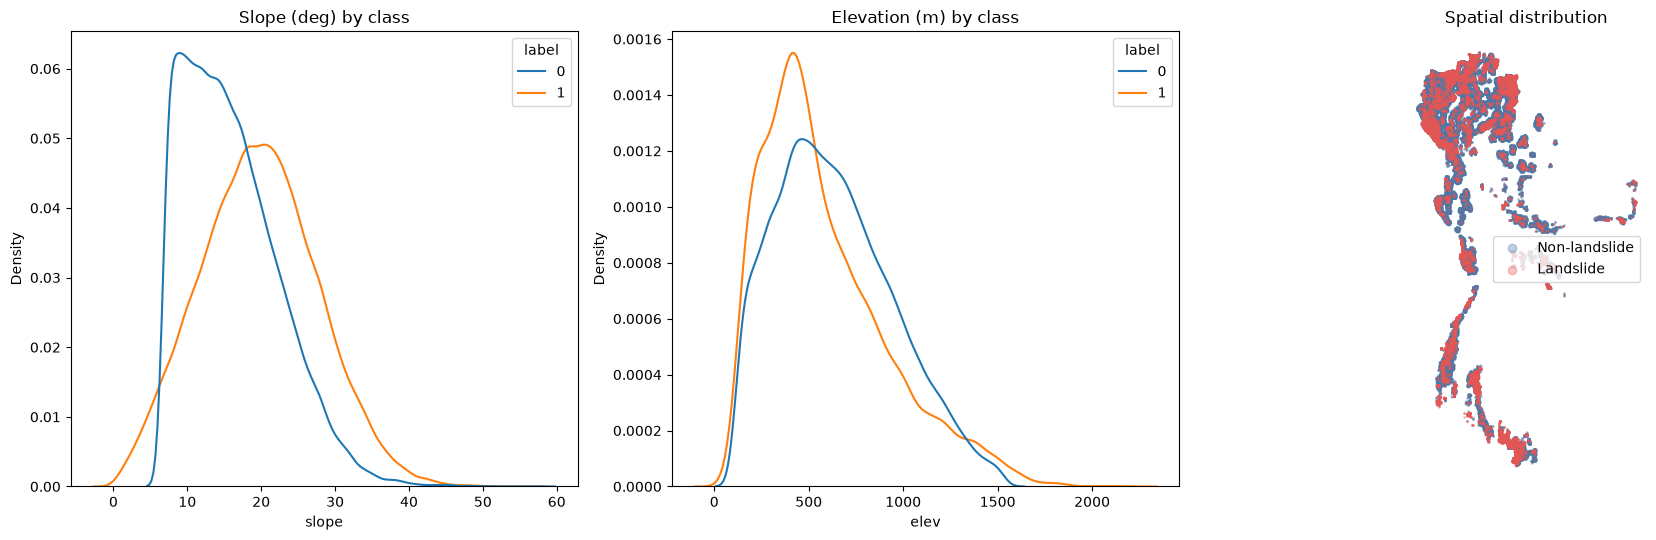


Land cover by class:
label          0      1     All
landcover                      
10.0       50771  51672  102443
20.0          11      0      11
30.0        3709   3034    6743
40.0         298     83     381
50.0          24     28      52
60.0           8      3      11
95.0           0      1       1
All        54821  54821  109642


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

sns.kdeplot(data=combined, x="slope", hue="label", common_norm=False, ax=axes[0])
axes[0].set_title("Slope (deg) by class")
sns.kdeplot(data=combined, x="elev", hue="label", common_norm=False, ax=axes[1])
axes[1].set_title("Elevation (m) by class")

combined[combined.label == 0].plot(ax=axes[2], markersize=1, alpha=0.35, color="#4C78A8", label="Non-landslide")
combined[combined.label == 1].plot(ax=axes[2], markersize=1, alpha=0.35, color="#E45756", label="Landslide")
axes[2].legend(markerscale=6)
axes[2].set_title("Spatial distribution")
axes[2].axis("off")

plt.tight_layout()
plt.show()

print("\nLand cover by class:")
print(pd.crosstab(combined["landcover"], combined["label"], margins=True))

## 7. Save susceptibility, recurrence and event-level tables

In [12]:
FINAL_COLUMNS = base_cols + model_factor_columns

def save_geocsv(gdf, path, columns):
    out = gdf[columns].copy()
    out["geometry"] = out.geometry.to_wkt()
    out.to_csv(path, index=False, encoding="utf-8-sig")

FINAL_CSV = PROCESSED_DIR / f"training_table_thailand_extended{SUFFIX}.csv"
FINAL_PARQUET = PROCESSED_DIR / f"training_table_thailand_extended{SUFFIX}.parquet"
save_geocsv(combined, FINAL_CSV, FINAL_COLUMNS)
pd.DataFrame(combined[FINAL_COLUMNS].drop(columns="geometry")).to_parquet(FINAL_PARQUET, index=False)

recurrence_table = combined.loc[combined["label"] == 1,
    ["location_id", "landslide_count", "recurrence_proxy_flag", "recurrence_class",
     "recurrence_weight", "X", "Y", "geometry"] + model_factor_columns].copy()
save_geocsv(recurrence_table, PROCESSED_DIR / f"thailand_landslide_recurrence_table{SUFFIX}.csv",
            recurrence_table.columns.tolist())

print("Saved:", FINAL_CSV.name, combined[FINAL_COLUMNS].shape)
print("Saved:", FINAL_PARQUET.name)
print("Saved recurrence table:", recurrence_table.shape)

Saved: training_table_thailand_extended_v2.csv (109642, 24)
Saved: training_table_thailand_extended_v2.parquet
Saved recurrence table: (54821, 21)


## 8. Leakage-safe train/test split and preprocessing

Identical to `07c` (stratified 80/20 on unique locations; scaler and one-hot encoder fitted on the training split
only). Rows with missing factor values are dropped. `08c` additionally runs spatial block CV, which matters even
more with harder negatives.

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import joblib

meta_cols = ["location_id", "landslide_count", "recurrence_proxy_flag", "recurrence_class", "recurrence_weight"]

model_df = pd.read_csv(FINAL_CSV)[meta_cols + ["label"] + model_factor_columns].copy()
print("Before dropna:", model_df.shape)
model_df = model_df.dropna(subset=model_factor_columns)
print("After dropna :", model_df.shape)
print(model_df["label"].value_counts().to_string())

train_idx, test_idx = train_test_split(
    model_df.index.to_numpy(), test_size=0.20, stratify=model_df["label"], random_state=RANDOM_STATE)
train_df, test_df = model_df.loc[train_idx].copy(), model_df.loc[test_idx].copy()

overlap = set(train_df["location_id"]) & set(test_df["location_id"])
if overlap:
    raise ValueError(f"Location leakage: {len(overlap)} ids in both splits")

X_train, X_test = train_df[model_factor_columns].copy(), test_df[model_factor_columns].copy()
y_train, y_test = train_df["label"].copy(), test_df["label"].copy()

if USE_RECURRENCE_SAMPLE_WEIGHT:
    sample_weight_train = train_df["recurrence_weight"].astype(float)
    sample_weight_test = test_df["recurrence_weight"].astype(float)
else:
    sample_weight_train = pd.Series(1.0, index=train_df.index)
    sample_weight_test = pd.Series(1.0, index=test_df.index)

preprocessor = ColumnTransformer([
    ("continuous", StandardScaler(), continuous_factor_columns),
    ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_factor_columns),
], remainder="drop")

X_train_processed = pd.DataFrame(preprocessor.fit_transform(X_train),
                                 columns=preprocessor.get_feature_names_out(), index=X_train.index)
X_test_processed = pd.DataFrame(preprocessor.transform(X_test),
                                columns=preprocessor.get_feature_names_out(), index=X_test.index)

print("\nTrain:", X_train.shape, y_train.value_counts().to_dict())
print("Test :", X_test.shape, y_test.value_counts().to_dict())
print("Processed:", X_train_processed.shape, X_test_processed.shape)

Before dropna: (109642, 19)
After dropna : (109629, 19)
label
0    54820
1    54809

Train: (87703, 13) {0: 43856, 1: 43847}
Test : (21926, 13) {0: 10964, 1: 10962}
Processed: (87703, 27) (21926, 27)


In [14]:
def out(name):
    return PROCESSED_DIR / f"{name}{SUFFIX}.csv"

X_train.to_csv(out("X_train_raw"), index=False)
X_test.to_csv(out("X_test_raw"), index=False)
y_train.to_csv(out("y_train"), index=False)
y_test.to_csv(out("y_test"), index=False)
X_train_processed.to_csv(out("X_train_processed"), index=False)
X_test_processed.to_csv(out("X_test_processed"), index=False)
sample_weight_train.rename("sample_weight").to_csv(out("sample_weight_train"), index=False)
sample_weight_test.rename("sample_weight").to_csv(out("sample_weight_test"), index=False)

audit_cols = ["location_id", "label", "landslide_count", "recurrence_proxy_flag", "recurrence_class", "recurrence_weight"]
train_df[audit_cols].to_csv(out("train_location_metadata"), index=False)
test_df[audit_cols].to_csv(out("test_location_metadata"), index=False)

joblib.dump(preprocessor, PROCESSED_DIR / f"preprocessor{SUFFIX}.pkl")

manifest = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "version": "v2_terrain_realistic_negatives",
    "n_positive_unique_locations": int(len(positives)),
    "n_negative": int(len(negatives)),
    "negative_sampling": {
        "exclusion_buffer_m": EXCLUSION_BUFFER_M,
        "coverage_buffer_m": COVERAGE_BUFFER_M,
        "slope_quantile_low": SLOPE_QUANTILE_LOW,
        "slope_min_deg": SLOPE_MIN,
        "elev_quantiles": list(ELEV_QUANTILES),
        "elev_range_m": [ELEV_MIN, ELEV_MAX],
        "excluded_landcover": EXCLUDE_LANDCOVER,
        "one_per_dem_cell": True,
        "random_state": RANDOM_STATE,
        "candidate_funnel": funnel,
    },
    "dem_resolution_m": REF_RES,
    "continuous_factors": continuous_factor_columns,
    "categorical_factors": categorical_factor_columns,
    "recurrence_used_as_standard_predictor": False,
    "single_feature_auc_v2": auc_new["v2 (this notebook)"].round(4).to_dict(),
    "slope_elev_tree_auc_v2": round(float(tree_new), 4),
    "slope_elev_tree_auc_07c": None if tree_old is None else round(float(tree_old), 4),
}
(PROCESSED_DIR / f"thailand_dataset_manifest{SUFFIX}.json").write_text(
    json.dumps(manifest, indent=2, default=str), encoding="utf-8")

print("Saved splits, weights, audit metadata, preprocessor and manifest with suffix:", repr(SUFFIX))

Saved splits, weights, audit metadata, preprocessor and manifest with suffix: '_v2'


## 9. (Optional) Promote v2 to the standard file names

`08c` reads `X_train_processed.csv`, `y_train.csv`, `preprocessor.pkl`, etc., and `09` reads
`training_table_thailand_extended.csv`. Set `PROMOTE_TO_STANDARD_NAMES = True` in the config cell and re-run this cell
to copy the v2 files over those names. Any existing standard file is first backed up once as `*_v1_random_neg.*`.

In [15]:
PROMOTE_FILES = [
    "training_table_thailand_extended.csv", "training_table_thailand_extended.parquet",
    "thailand_landslide_recurrence_table.csv",
    "X_train_raw.csv", "X_test_raw.csv", "y_train.csv", "y_test.csv",
    "X_train_processed.csv", "X_test_processed.csv",
    "sample_weight_train.csv", "sample_weight_test.csv",
    "train_location_metadata.csv", "test_location_metadata.csv",
    "preprocessor.pkl",
]

if PROMOTE_TO_STANDARD_NAMES and SUFFIX:
    for name in PROMOTE_FILES:
        standard = PROCESSED_DIR / name
        v2 = PROCESSED_DIR / (standard.stem + SUFFIX + standard.suffix)
        if not v2.exists():
            print("skip (not found):", v2.name)
            continue
        if standard.exists():
            backup = PROCESSED_DIR / (standard.stem + "_v1_random_neg" + standard.suffix)
            if not backup.exists():
                shutil.copy2(standard, backup)
        shutil.copy2(v2, standard)
        print("promoted:", v2.name, "->", standard.name)
else:
    print("Not promoting. Point 08c/09 at the *" + SUFFIX + " files, or set PROMOTE_TO_STANDARD_NAMES=True and re-run this cell.")

Not promoting. Point 08c/09 at the *_v2 files, or set PROMOTE_TO_STANDARD_NAMES=True and re-run this cell.


## Expected outcome and how to use it

1. Re-run `08c` on these files. Held-out ROC-AUC should fall clearly below the old ≈ 0.97 because the shortcut
   is gone. That is the honest within-Thailand number.
2. Re-run `09`. If zero-shot transfer AUC rises above ≈ 0.6, the earlier failure was largely a label-difficulty
   mismatch. If it stays near chance, the remaining causes are feature-scale mismatch (90 m vs 30 m terrain,
   Sri Lanka TWI) and genuine domain shift.
3. Compare sampling strategies by changing `COVERAGE_BUFFER_M` (e.g. 5 km / 10 km / `None`) and
   `SLOPE_QUANTILE_LOW` (0.0 / 0.05 / 0.10). Keep whichever you can justify, and report the sensitivity.